**BB84 Quantum Key Distribution**

**References**
1. Lo, Hoi-Kwong, Chau, H. F., and Ardehali, M. (November 26, 2024). *Effecient Quantum Key Distribution Scheme and Proof of its Unconditional Security*. 
2. Gao, T., Rickert, L., Urban, F. et. al.

In [3]:
# imports for quantum circuit construction
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp # observables
from qiskit.transpiler import generate_preset_pass_manager # transpiler
from qiskit_ibm_runtime import QiskitRuntimeService # runtime service
from qiskit.primitives import StatevectorSampler # sampler

# plotting imports
from matplotlib import pyplot as plt

# Runtime imports
from qiskit_ibm_runtime.options_models import EstimatorOptions
from qiskit_ibm_runtime.executor_estimator import Estimator
from qiskit_ibm_runtime.executor_sampler import Sampler

In [5]:
# Global configuration variables

SIM_BACKEND = False # Set to True to use a simulator, False to use a real backend. If True, the code will use the FakeBelemV2 backend. If False, it will use the least busy operational backend.
QUBITS = 1 # Number of qubits to use in the circuit.
RESILIENCE_LEVEL = 1 # Resilience level for the Estimator. 0 = no resilience, 1 = readout error mitigation, 2 = gate error mitigation, 3 = both readout and gate error mitigation.
SHOTS = 1024 # Number of shots to use for the Sampler OR Estimator. This is the number of times the circuit will be run to collect measurement statistics.
PHYSICAL_QUBIT = 0 # The qubit used in circuit. This is the physical qubit on the backend that will be used for the circuit. It is important to choose a qubit with low error rates and good connectivity to other qubits if needed.
QPU = "ibm_fez"

In [6]:
# Initialize the Qiskit Runtime Service and select the backend based on the SIM_BACKEND flag.

service = QiskitRuntimeService()
if SIM_BACKEND:
    from qiskit_ibm_runtime.fake_provider import FakeBelemV2
    backend = FakeBelemV2()
else:
    backend = service.backend(QPU) # can fail when no matching simulator exists.

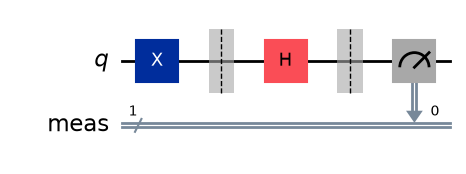

In [ ]:
# Build Alice's qubits and show circuit (local simulation)

alice = QuantumCircuit(QUBITS) # Initialize Alice at |0>

alice.x(0)  # Bit flip to |1>
alice.barrier() # Barrier to separate preparation from measurement
alice.h(0)  # Hadamard to |+>
#alice.h(0)  # Hadamard |+> to |0>
#alice.z(0)  # Phase flip to |->
#alice.s(0)  # Phase gate to |i>
#alice.y(0)  # Y gate to |+i>
#alice.xcx(0, 1)  # CNOT to entangle qubits 0 and 1
#alice.zcx(0, 1)  # Controlled-Z to entangle qubits 0 and 1
alice.measure_all()
alice.draw("mpl")

In [53]:
# Ideal sampler (no error) for Alice's circuit (local simulation)
sampler = StatevectorSampler()
result = sampler.run([alice], shots=1024).result()
print(result[0].data.meas.get_counts())

{'1': 521, '0': 503}


In [35]:
# Set up bases for different observables.

observables_labels = ["Z", "X", "Y"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [248]:
# ZZII...II, ZIZI...II, ... , ZIII...IZ
operator_strings = [
    "Z" + "I" * i + "Z" + "I" * (n - 2 - i) for i in range(n - 1)
]

operators = [SparsePauliOp(operator) for operator in operator_strings]

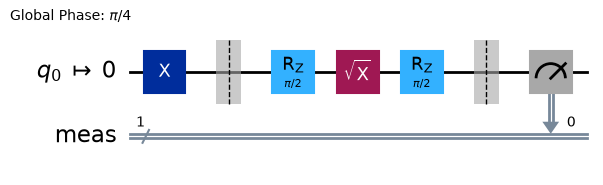

In [54]:
# Build Alice's circuit for the Estimator and Sampler primitives.

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1,
    initial_layout=[PHYSICAL_QUBIT]
)

isa_circuit_alice = pm.run(alice)
isa_circuit_alice.draw("mpl", idle_wires=False)

In [55]:
# Error Rate Calculation |0>
sampler = Sampler(mode=backend)
job_alice = sampler.run([isa_circuit_alice], shots=1024)
print("Job ID:", job_alice.job_id())

counts = job_alice.result()[0].data.meas.get_counts()
error_rate = counts.get("1", 0) / sum(counts.values())

print("Counts:", counts)
print(f"|0> error rate: {error_rate:.2%}")

Job ID: dbdvdhvpc3tc739krfb0
Counts: {'1': 487, '0': 537}
|0> error rate: 47.56%


In [30]:
# Error Rate Calculation |1>
sampler = Sampler(mode=backend)
job_alice = sampler.run([isa_circuit_alice], shots=1024)
print("Job ID:", job_alice.job_id())

counts = job_alice.result()[0].data.meas.get_counts()
error_rate = counts.get("0", 0) / sum(counts.values())

print("Counts:", counts)
print(f"|1> error rate: {error_rate:.2%}")

Job ID: dbdv8q7pc3tc739kr9q0
Counts: {'1': 1004, '0': 20}
|1> error rate: 1.95%


In [221]:
# Construct the Estimator instance.
estimator = Estimator(mode=backend)
estimator.options.resilience_level = RESILIENCE_LEVEL
estimator.options.default_shots = SHOTS

# The observables are 2-qubit Pauli strings, so the circuit must also be 2 qubits.
mapped_observables = [
    observable.apply_layout(isa_circuit_alice.layout) for observable in observables
]

# One pub, with one circuit to run against five different observables.
job_alice = estimator.run([(isa_circuit_alice, mapped_observables)])

# Use the job ID to retrieve your job data later
print(f">>> Job ID: {job_alice.job_id()}")

>>> Job ID: dbduds7pc3tc739kq520


In [222]:
job_result_alice = job_alice.result() # get the result of the job
pub_result_alice = job_result_alice[0] # get the result for the first circuit (Alice's circuit)

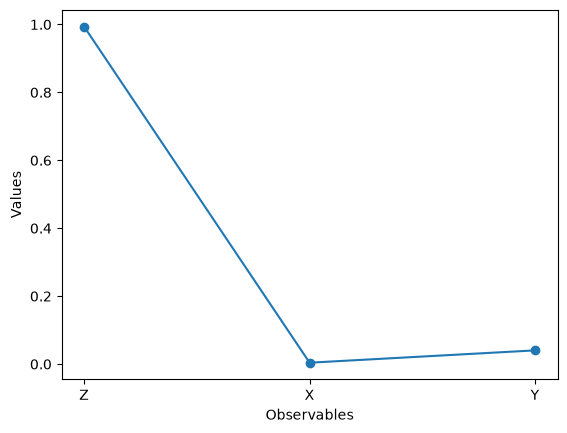

In [223]:
# Plot the result
values_alice = pub_result_alice.data.evs
errors_alice = pub_result_alice.data.stds

# plotting graph
# Each result contains 18 values in the order: [Eve(6), Bob(6), Alice(6)]
alice_values = values_alice[:len(observables_labels)]

plt.plot(observables_labels, alice_values, marker="o", label="Alice")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.show()

In [224]:
# Print the expectation values and standard deviations for each observable reads out [Z X Y]
print(job_result_alice[0].data.evs)
print(job_result_alice[0].data.stds)

[0.99345605 0.00403025 0.04030248]
[0.00710671 0.02625467 0.02968463]


In [ ]:
#for later
def get_qc_for_n_qubit_GHZ_state(n: int) -> QuantumCircuit:
    """This function will create a qiskit.QuantumCircuit (qc)
        for an n-qubit GHZ state.

    Args:
        n (int): Number of qubits in the n-qubit GHZ state

    Returns:
        QuantumCircuit: Quantum circuit that generate the n-qubit GHZ state,
            assuming all qubits start in the 0 state
    """
    if isinstance(n, int) and n >= 2:
        qc = QuantumCircuit(n)
        qc.h(0)
        for i in range(n - 1):
            qc.cx(i, i + 1)
    else:
        raise Exception("n is not a valid input")
    return qc


# Create a new circuit with 100 qubits in the GHZ state
n = QUBITS
qc = get_qc_for_n_qubit_GHZ_state(n)

Exception: n is not a valid input